## Error and Accuracy Assessment
For both age and harvest classifications

In [15]:
%matplotlib inline

import datacube
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# from dea_tools.plotting import rgb
# from dea_tools.plotting import rgb, display_map
# from matplotlib import colors as mcolours
# from dea_tools.landcover import plot_land_cover, lc_colourmap, make_colourbar

from sklearn.metrics import confusion_matrix   # this is the library we use for the Confusion matrix
import seaborn as sns


In [16]:

# load the results of the classification
harvest_class = pd.read_csv('Results/harvest_classification.csv')
age_class = pd.read_csv('Results/age_classification.csv')

# load the validation data
harvest_val = pd.read_csv('PJM-Rose-Farm-Data - Harvest.csv')
age_val = pd.read_csv('PJM-Rose-Farm-Data - Ages.csv')

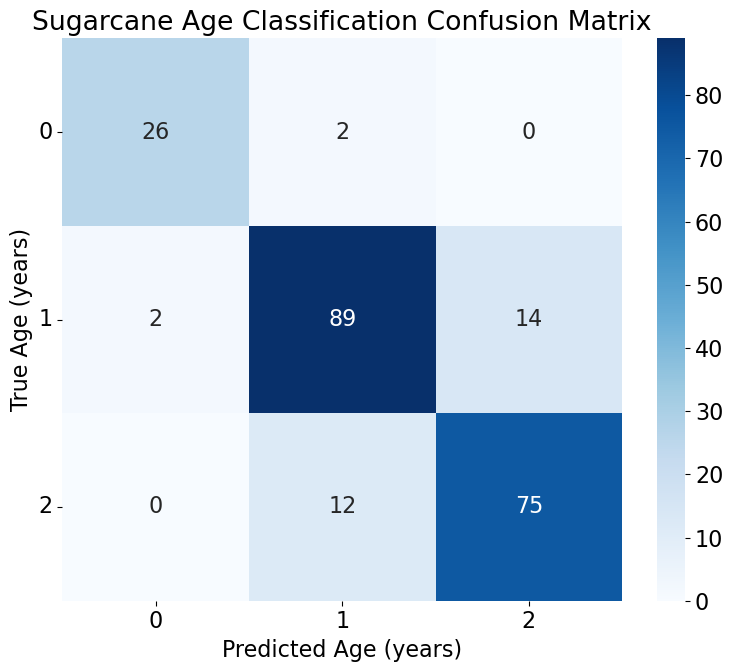

Overall accuracy: 86.36%
Total valid comparisons: 220


In [17]:
## AGE CLASSIFICATION ANALYSIS

years = np.arange(2016, 2024) # data not available for 2024 or 2025
years = years[years != 2018] # skip 2018 as that was used for training


true_ages = []
pred_ages = []

# Match paddocks by ID
pred_lookup = age_class.set_index("C_LINKCODE")

for year in years:
    year = str(year)

    for _, row in age_val.iterrows():
        paddock = row["C_LINKCODE"]
        true_age = row[year]

        if paddock not in pred_lookup.index:
            continue

        predict_age = pred_lookup.loc[paddock, year]

        # Skip missing values
        if pd.isna(true_age) or pd.isna(predict_age):
            continue

        true_ages.append(int(true_age))
        pred_ages.append(int(predict_age))

# Calculate confusion matrix
class_labels = [0, 1, 2]

cm = confusion_matrix(
    true_ages,
    pred_ages,
    labels=class_labels
)

# Plot confusion matrix
plt.figure(figsize=(8, 7))
plt.rcParams['font.size'] = 16 

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title('Sugarcane Age Classification Confusion Matrix')
plt.xlabel('Predicted Age (years)')
plt.ylabel('True Age (years)')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('Results/age_confusion_matrix.png')
plt.show()

# Overall accuracy
accuracy = np.trace(cm) / cm.sum() * 100 if cm.sum() > 0 else np.nan

print(f"Overall accuracy: {accuracy:.2f}%")
print(f"Total valid comparisons: {cm.sum()}")

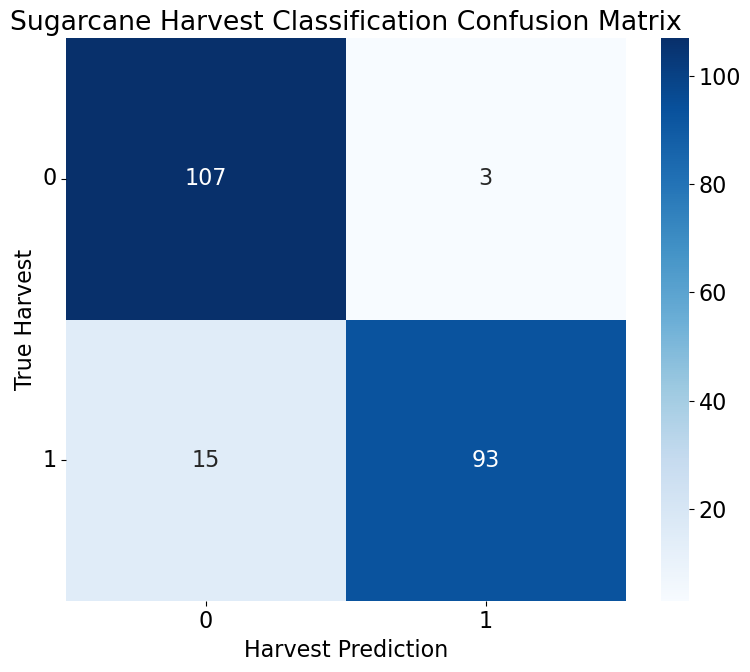

Overall accuracy: 91.74%
Total valid comparisons: 218


In [18]:
## HARVEST CLASSIFICATION ANALYSIS

years = np.arange(2016, 2023) # data not available for 2023, 2024 or 2025

true_harvs = []
pred_harvs = []

# Match paddocks by ID
pred_lookup = harvest_class.set_index("C_LINKCODE")

for year in years:
    year = str(year)

    for _, row in harvest_val.iterrows():
        paddock = row["C_LINKCODE"]
        true_harv = row[year]

        if paddock not in pred_lookup.index:
            continue

        predict_harv = pred_lookup.loc[paddock, year]

        # Skip missing values
        if pd.isna(true_harv) or pd.isna(predict_harv):
            continue

        true_harvs.append(int(true_harv))
        pred_harvs.append(int(predict_harv))

# Calculate confusion matrix
class_labels = [0, 1]

cm = confusion_matrix(
    true_harvs,
    pred_harvs,
    labels=class_labels
)

# Plot confusion matrix
plt.figure(figsize=(8, 7))
plt.rcParams['font.size'] = 16 

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title('Sugarcane Harvest Classification Confusion Matrix')
plt.xlabel('Harvest Prediction')
plt.ylabel('True Harvest')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('Results/harvest_confusion_matrix.png')
plt.show()

# Overall accuracy
accuracy = np.trace(cm) / cm.sum() * 100 if cm.sum() > 0 else np.nan

print(f"Overall accuracy: {accuracy:.2f}%")
print(f"Total valid comparisons: {cm.sum()}")